In [1]:
from pathlib import Path
import pandas as pd

project = Path(r"C:\Users\redhu\OneDrive\Desktop\Bearing_fault_detection")
registry = pd.read_csv(project / "metadata/recording_registry.csv")

development = registry[
    registry["partition"].eq("development")
    & registry["eligible_for_analysis"].eq(True)
].copy()

print("Eligible development recordings:", len(development))

Eligible development recordings: 272


In [2]:
same_setting = development[
    development["speed_code"].eq("N15")
    & development["torq_code"].eq("M07")
    & development["force_code"].eq("F10")
]

example_records = same_setting.sort_values(
    ["bearing_id", "recording_no"]
).drop_duplicates("bearing_id")

example_records[["recording_id", "bearing_id", "condition"]]

,recording_id,bearing_id,condition
60,N15_M07_F10_K001_1,K001,healthy
140,N15_M07_F10_K002_1,K002,healthy
300,N15_M07_F10_KA04_1,KA04,faulty
460,N15_M07_F10_KI04_1,KI04,faulty


In [3]:
from scipy.io import loadmat

def load_signal(path):
    recording = loadmat(path)[path.stem][0, 0]
    channels = recording["Y"].ravel()
    names = [channel["Name"].item() for channel in channels]
    vibration = channels[names.index("vibration_1")]
    return vibration["Data"].ravel().astype(float)

signals = {}
for _, record in example_records.iterrows():
    path = project / "data/raw/paderborn" / record["relative_path"]
    signals[record["bearing_id"]] = load_signal(path)
    print(record["bearing_id"], "— samples:", signals[record["bearing_id"]].size)

K001 — samples: 256001
K002 — samples: 256001
KA04 — samples: 256004
KI04 — samples: 256001


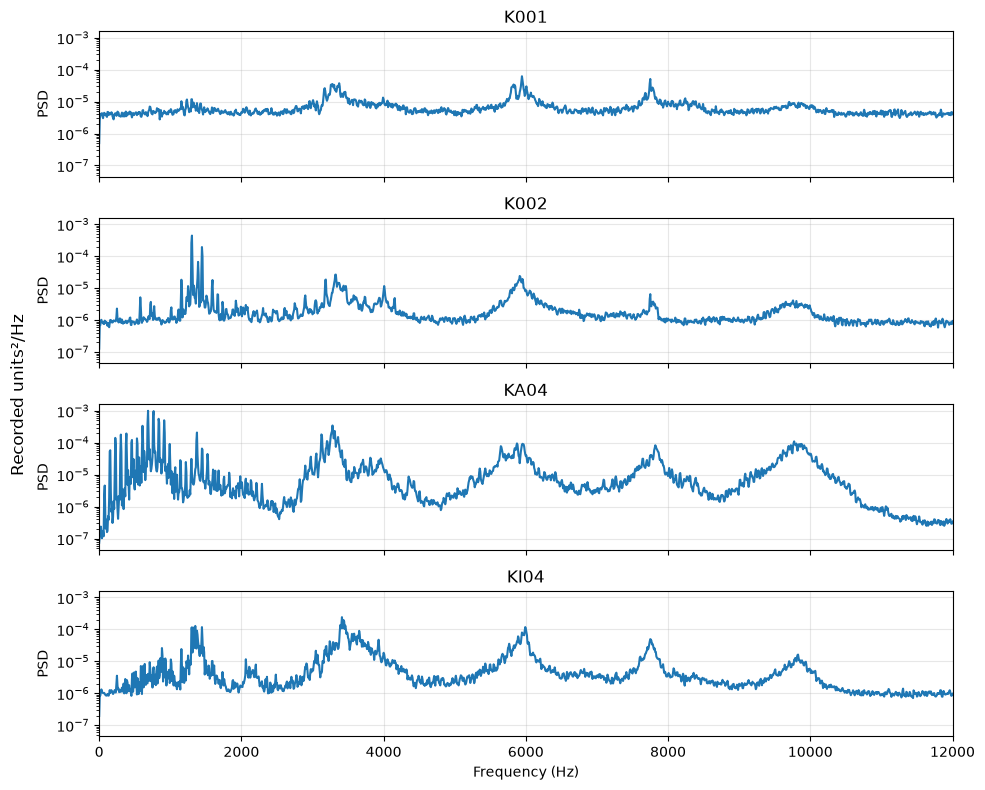

In [4]:
import matplotlib.pyplot as plt
from scipy.signal import welch

fs = float(example_records["nominal_fs_hz"].iloc[0])
assert example_records["nominal_fs_hz"].nunique() == 1

psds = {}
fig, axes = plt.subplots(4, 1, figsize=(10, 8), sharex=True, sharey=True)

for ax, (bearing, x) in zip(axes, signals.items()):
    frequency, power = welch(
        x, fs=fs, window="hann", nperseg=8192, noverlap=4096
    )
    psds[bearing] = power
    ax.semilogy(frequency, power)
    ax.set_title(bearing)
    ax.set_ylabel("PSD")
    ax.grid(alpha=0.3)

axes[-1].set(xlim=(0, 12000), xlabel="Frequency (Hz)")
fig.supylabel("Recorded units²/Hz")
plt.tight_layout()
plt.show()

In [5]:
from scipy.signal import butter, sosfiltfilt

sos = butter(
    4, [5000, 7000], btype="bandpass", fs=fs, output="sos"
)

filtered = {}
for bearing, x in signals.items():
    filtered[bearing] = sosfiltfilt(sos, x - x.mean())

In [6]:
import numpy as np
from scipy.signal import hilbert

padding = int(0.1 * fs)
envelopes = {}

for bearing, x in filtered.items():
    padded = np.pad(x, padding, mode="reflect")
    envelopes[bearing] = np.abs(hilbert(padded))[padding:-padding]
    print(bearing, "— envelope samples:", envelopes[bearing].size)

K001 — envelope samples: 256001
K002 — envelope samples: 256001
KA04 — envelope samples: 256004
KI04 — envelope samples: 256001


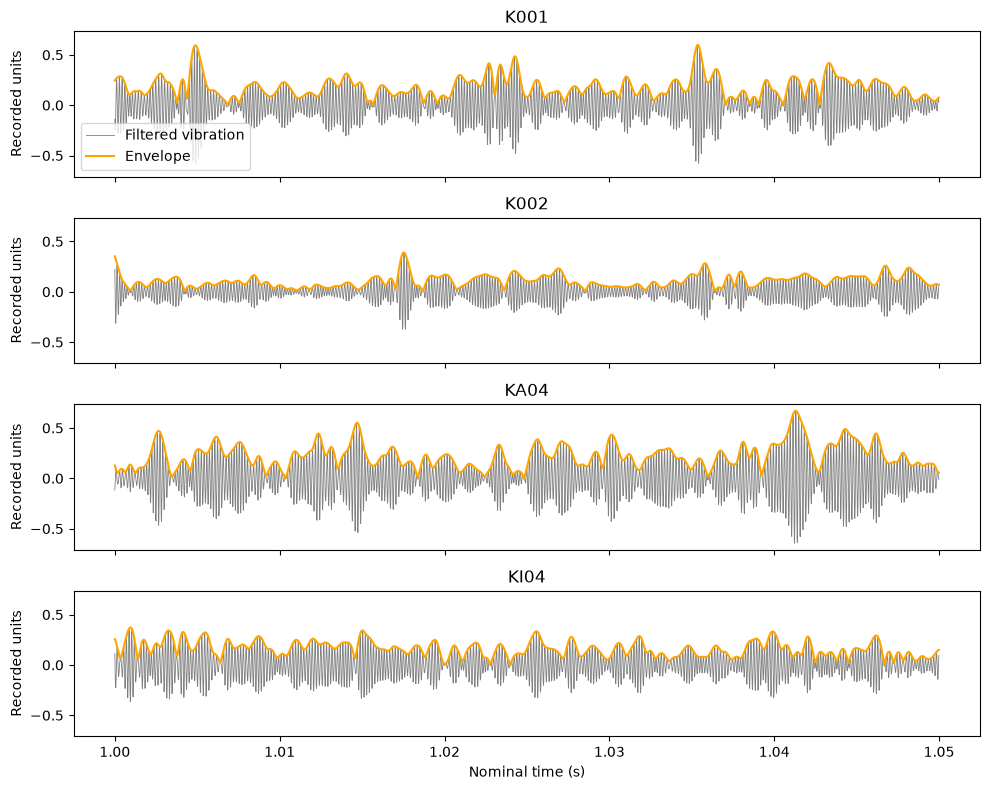

In [7]:
fig, axes = plt.subplots(4, 1, figsize=(10, 8), sharex=True, sharey=True)

for ax, (bearing, x) in zip(axes, filtered.items()):
    t = np.arange(x.size) / fs
    keep = (t >= 1.00) & (t < 1.05)
    ax.plot(t[keep], x[keep], color="gray", linewidth=0.6, label="Filtered vibration")
    ax.plot(t[keep], envelopes[bearing][keep], color="orange", label="Envelope")
    ax.set_title(bearing)
    ax.set_ylabel("Recorded units")

axes[0].legend()
axes[-1].set_xlabel("Nominal time (s)")
plt.tight_layout()
plt.show()

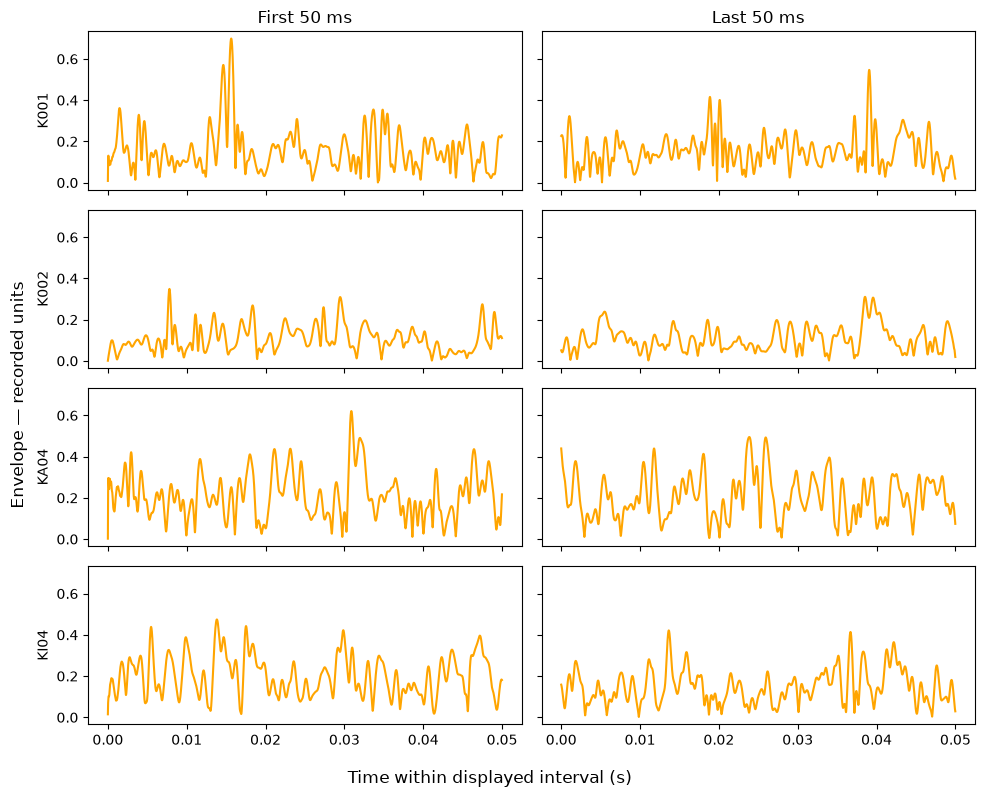

In [8]:
edge_samples = int(0.05 * fs)
t_edge = np.arange(edge_samples) / fs
fig, axes = plt.subplots(4, 2, figsize=(10, 8), sharex=True, sharey=True)

for i, (bearing, envelope) in enumerate(envelopes.items()):
    axes[i, 0].plot(t_edge, envelope[:edge_samples], color="orange")
    axes[i, 1].plot(t_edge, envelope[-edge_samples:], color="orange")
    axes[i, 0].set_ylabel(bearing)

axes[0, 0].set_title("First 50 ms")
axes[0, 1].set_title("Last 50 ms")
fig.supxlabel("Time within displayed interval (s)")
fig.supylabel("Envelope — recorded units")
plt.tight_layout()
plt.show()

In [9]:
guard = int(0.1 * fs)
interior_envelopes = {}

for bearing, envelope in envelopes.items():
    interior_envelopes[bearing] = envelope[guard:-guard]
    print(bearing, "— retained samples:", interior_envelopes[bearing].size)

K001 — retained samples: 243201
K002 — retained samples: 243201
KA04 — retained samples: 243204
KI04 — retained samples: 243201


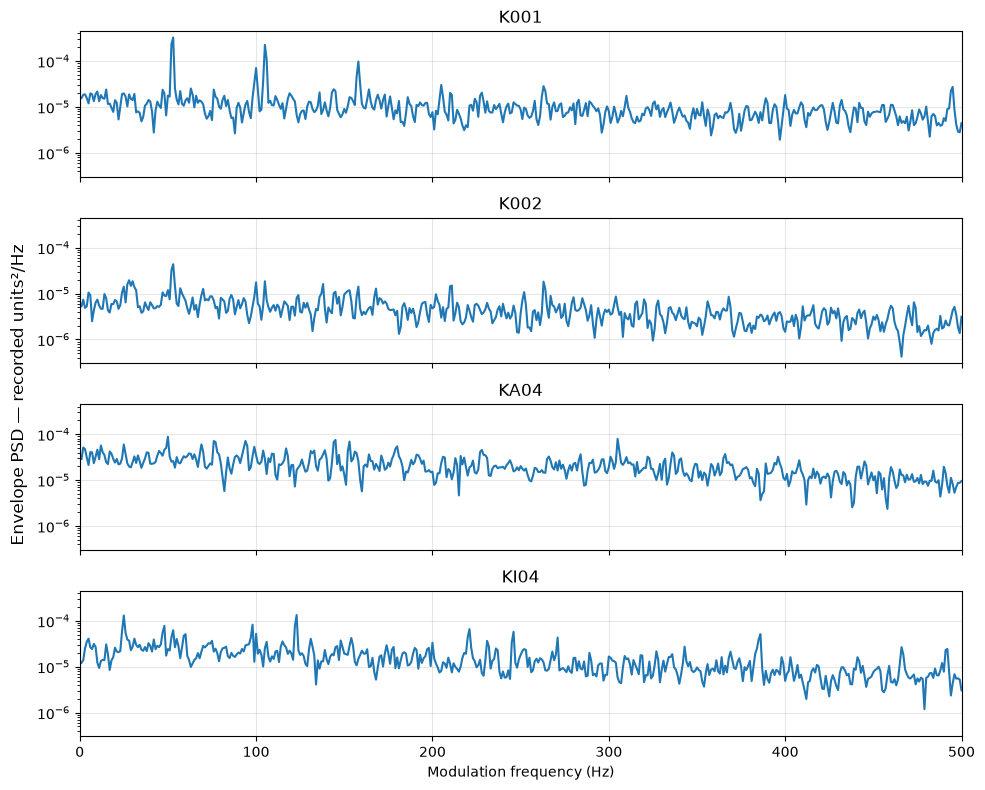

In [10]:
segment = int(fs)
envelope_psds = {}
fig, axes = plt.subplots(4, 1, figsize=(10, 8), sharex=True, sharey=True)

for ax, (bearing, envelope) in zip(axes, interior_envelopes.items()):
    f_env, p_env = welch(
        envelope, fs=fs, window="hann",
        nperseg=segment, noverlap=segment // 2,
        detrend="constant"
    )
    envelope_psds[bearing] = p_env
    view = (f_env >= 1) & (f_env <= 500)
    ax.semilogy(f_env[view], p_env[view])
    ax.set_title(bearing)
    ax.grid(alpha=0.3)

axes[-1].set(xlim=(0, 500), xlabel="Modulation frequency (Hz)")
fig.supylabel("Envelope PSD — recorded units²/Hz")
plt.tight_layout()
plt.show()

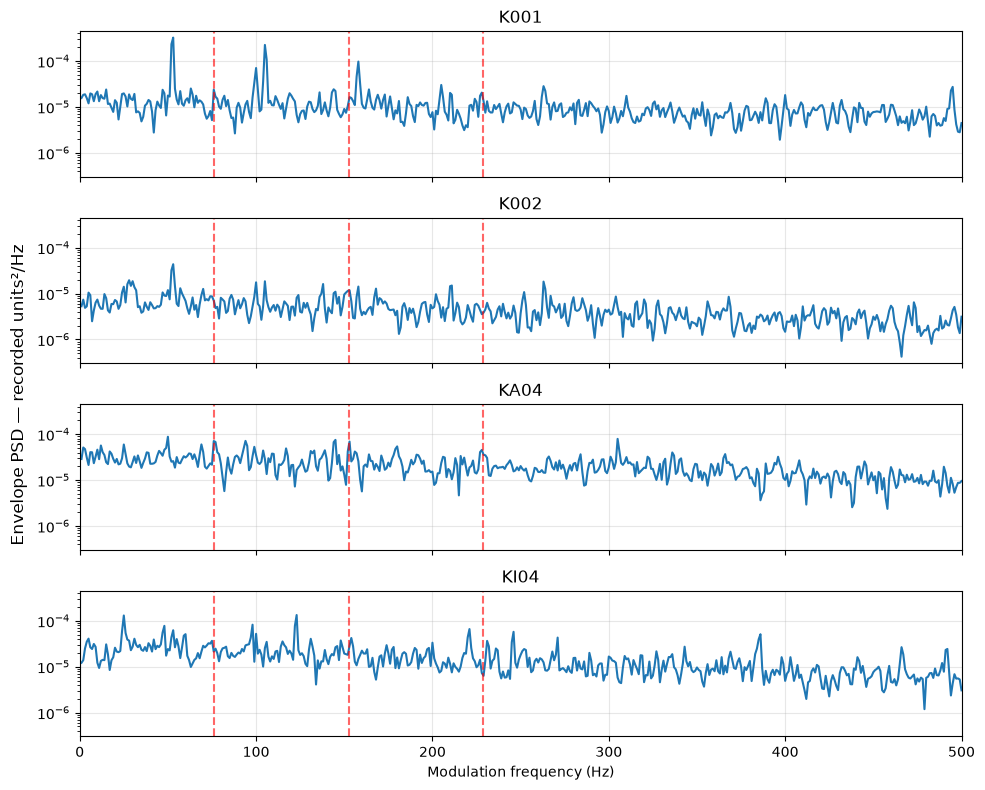

In [11]:
bpfo_reference = 76.25

for ax in axes:
    for harmonic in [1, 2, 3]:
        ax.axvline(
            harmonic * bpfo_reference,
            color="red", linestyle="--", alpha=0.6
        )

display(fig)

In [12]:
distance = np.abs(f_env - bpfo_reference)
peak_band = distance <= 3
background = (distance >= 5) & (distance <= 15)

checks = []
for bearing, power in envelope_psds.items():
    values = power[peak_band]
    checks.append({
        "Bearing": bearing,
        "Peak frequency (Hz)": f_env[peak_band][values.argmax()],
        "Peak/background": values.max() / np.median(power[background])
    })

pd.DataFrame(checks).round(2)

,Bearing,Peak frequency (Hz),Peak/background
0,K001,76.0,2.02
1,K002,74.0,1.53
2,KA04,76.0,2.37
3,KI04,75.0,2.05


In [13]:
def vibration_envelope(x, low=9000, high=11000, padding_s=0.1):
    padding = int(padding_s * fs)
    sos = butter(4, [low, high], btype="bandpass", fs=fs, output="sos")
    filtered = sosfiltfilt(sos, x - x.mean())
    padded = np.pad(filtered, padding, mode="reflect")
    return np.abs(hilbert(padded))[padding:-padding]


def envelope_psd(x, low, high, guard_s=0.1, padding_s=0.1):
    envelope = vibration_envelope(x, low, high, padding_s)
    guard = int(guard_s * fs)
    return welch(
        envelope[guard:-guard], fs=fs, window="hann",
        nperseg=segment, noverlap=segment // 2,
        detrend="constant"
    )

In [14]:
band_checks = []

for low, high in [(5000, 7000), (9000, 11000)]:
    for bearing, x in signals.items():
        f_band, p_band = envelope_psd(x, low, high)
        distance = np.abs(f_band - bpfo_reference)
        peak = distance <= 3
        background = (distance >= 5) & (distance <= 15)
        values = p_band[peak]

        band_checks.append({
            "Carrier band": f"{low}-{high} Hz",
            "Bearing": bearing,
            "Peak frequency (Hz)": f_band[peak][values.argmax()],
            "Peak/background": values.max() / np.median(p_band[background])
        })

band_comparison = pd.DataFrame(band_checks)
band_comparison.round(2)

,Carrier band,Bearing,Peak frequency (Hz),Peak/background
0,5000-7000 Hz,K001,76.0,2.02
1,5000-7000 Hz,K002,74.0,1.53
2,5000-7000 Hz,KA04,76.0,2.37
3,5000-7000 Hz,KI04,75.0,2.05
4,9000-11000 Hz,K001,78.0,1.40
5,9000-11000 Hz,K002,76.0,2.14
6,9000-11000 Hz,KA04,76.0,357.12
7,9000-11000 Hz,KI04,75.0,5.23


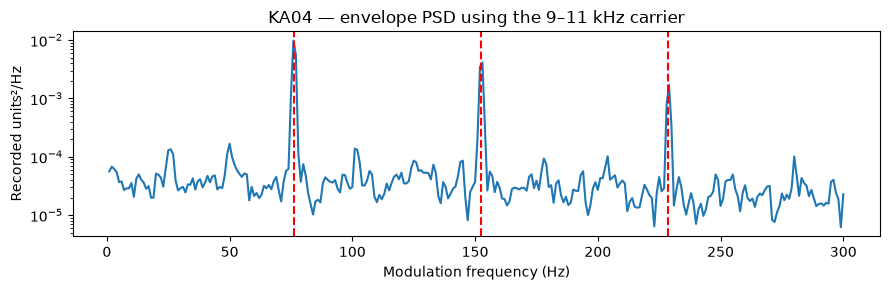

In [15]:
f_check, p_check = envelope_psd(signals["KA04"], 9000, 11000)
view = (f_check >= 1) & (f_check <= 300)

plt.figure(figsize=(9, 3))
plt.semilogy(f_check[view], p_check[view])

for harmonic in [1, 2, 3]:
    plt.axvline(harmonic * bpfo_reference, color="red", linestyle="--")

plt.title("KA04 — envelope PSD using the 9–11 kHz carrier")
plt.xlabel("Modulation frequency (Hz)")
plt.ylabel("Recorded units²/Hz")
plt.tight_layout()
plt.show()

In [16]:
def peak_ratio(frequency, power, target):
    distance = np.abs(frequency - target)
    peak = power[distance <= 3].max()
    background = np.median(power[(distance >= 5) & (distance <= 15)])
    assert background > 0, "Invalid spectral background."
    return peak / background

In [17]:
repeat_checks = []

for _, record in same_setting.iterrows():
    path = project / "data/raw/paderborn" / record["relative_path"]
    f, p = envelope_psd(load_signal(path), 9000, 11000)
    repeat_checks.append({
        "recording_id": record["recording_id"],
        "bearing_id": record["bearing_id"],
        "condition": record["condition"],
        "BPFO peak/background": peak_ratio(f, p, bpfo_reference)
    })

repeat_results = pd.DataFrame(repeat_checks)
repeat_results.groupby(["bearing_id", "condition"])[
    "BPFO peak/background"
].agg(["count", "median", "min", "max"]).round(2)

,,count,median,min,max
bearing_id,condition,,,,
K001,healthy,16,1.41,0.88,1.86
K002,healthy,19,1.90,1.26,3.33
KA04,faulty,18,279.31,207.25,373.49
KI04,faulty,17,3.62,0.89,5.56


In [18]:
assert development["nominal_fs_hz"].eq(fs).all()
bpfo_checks = []

for _, record in development.iterrows():
    path = project / "data/raw/paderborn" / record["relative_path"]
    f, p = envelope_psd(load_signal(path), 9000, 11000)
    target = bpfo_reference * record["speed_setting_rpm"] / 1500

    result = record.to_dict()
    result["Expected BPFO (Hz)"] = target
    result["BPFO peak/background"] = peak_ratio(f, p, target)
    bpfo_checks.append(result)

bpfo_results = pd.DataFrame(bpfo_checks)
bpfo_results.groupby(
    ["speed_code", "torq_code", "force_code", "bearing_id"]
)["BPFO peak/background"].agg(["count", "median", "min", "max"]).round(2)

count  median     min     max
speed_code torq_code force_code bearing_id                               
N09        M07       F10        K001           16    7.07    4.54   10.42
                                K002           18   11.29    7.79   14.99
                                KA04           19  136.66    9.65  239.68
                                KI04           16    9.46    7.08   12.78
N15        M01       F10        K001           16    1.54    0.99    3.19
                                K002           18    2.09    0.91    4.12
                                KA04           17  531.93  411.52  710.61
                                KI04           19    4.29    2.16    5.95
           M07       F04        K001           10    1.56    0.92    2.54
                                K002           20    2.40    1.05    3.15
                                KA04           18  154.01  116.46  190.60
                                KI04           15    2.83    1.76    5.35
                     F10        K001           16    1.41    0.88    1.86
                                K002           19    1.90    1.26    3.33
                                KA04           18  279.31  207.25  373.49
                                KI04           17    3.62    0.89    5.56

In [19]:
weak = bpfo_results[
    bpfo_results["bearing_id"].eq("KA04")
    & bpfo_results["speed_code"].eq("N09")
].nsmallest(5, "BPFO peak/background")

weak[["recording_id", "Expected BPFO (Hz)", "BPFO peak/background"]]

,recording_id,Expected BPFO (Hz),BPFO peak/background
144,N09_M07_F10_KA04_13,45.75,9.654668
147,N09_M07_F10_KA04_16,45.75,84.458652
150,N09_M07_F10_KA04_19,45.75,107.755801
151,N09_M07_F10_KA04_20,45.75,113.040702
142,N09_M07_F10_KA04_11,45.75,116.790416


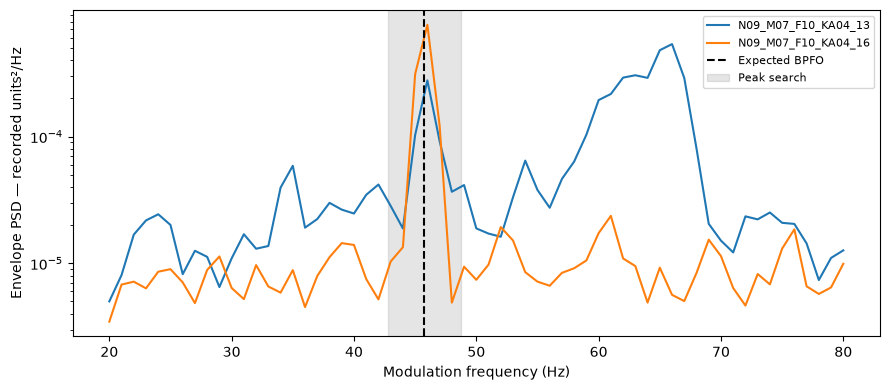

In [20]:
target = weak["Expected BPFO (Hz)"].iloc[0]
fig, ax = plt.subplots(figsize=(9, 4))

for _, record in weak.head(2).iterrows():
    path = project / "data/raw/paderborn" / record["relative_path"]
    f, p = envelope_psd(load_signal(path), 9000, 11000)
    view = (f >= 20) & (f <= 80)
    ax.semilogy(f[view], p[view], label=record["recording_id"])

ax.axvline(target, color="black", linestyle="--", label="Expected BPFO")
ax.axvspan(target - 3, target + 3, color="gray", alpha=0.2, label="Peak search")
ax.set(xlabel="Modulation frequency (Hz)", ylabel="Envelope PSD — recorded units²/Hz")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [21]:
harmonic_checks = []

for _, record in weak.head(2).iterrows():
    path = project / "data/raw/paderborn" / record["relative_path"]
    f, p = envelope_psd(load_signal(path), 9000, 11000)
    result = {"Recording": record["recording_id"]}

    for harmonic in [1, 2, 3]:
        result[f"{harmonic}x BPFO ratio"] = peak_ratio(f, p, harmonic * target)

    harmonic_checks.append(result)

pd.DataFrame(harmonic_checks).round(2)

,Recording,1x BPFO ratio,2x BPFO ratio,3x BPFO ratio
0,N09_M07_F10_KA04_13,9.65,9.56,1.19
1,N09_M07_F10_KA04_16,84.46,47.50,10.32


In [22]:
shaft_hz = 1500 / 60
balls = 8
ball_diameter = 6.75
pitch_diameter = 28.55

bpfi_reference = balls / 2 * shaft_hz * (1 + ball_diameter / pitch_diameter)
print("Approximate BPFI:", round(bpfi_reference, 2), "Hz")

Approximate BPFI: 123.64 Hz


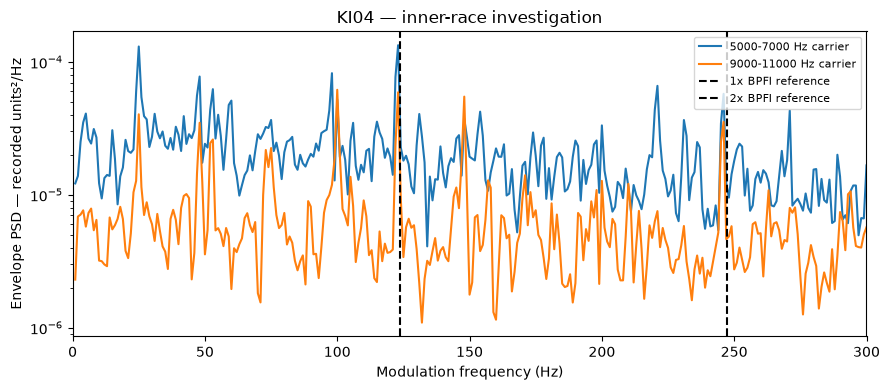

In [23]:
fig, ax = plt.subplots(figsize=(9, 4))

for low, high in [(5000, 7000), (9000, 11000)]:
    f, p = envelope_psd(signals["KI04"], low, high)
    view = (f >= 1) & (f <= 300)
    ax.semilogy(f[view], p[view], label=f"{low}-{high} Hz carrier")

for harmonic in [1, 2]:
    ax.axvline(
        harmonic * bpfi_reference, color="black",
        linestyle="--", label=f"{harmonic}x BPFI reference"
    )

ax.set(xlim=(0, 300), xlabel="Modulation frequency (Hz)",
       ylabel="Envelope PSD — recorded units²/Hz", title="KI04 — inner-race investigation")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [24]:
bpfi_checks = []

for low, high in [(5000, 7000), (9000, 11000)]:
    for bearing, x in signals.items():
        f, p = envelope_psd(x, low, high)
        near = np.abs(f - bpfi_reference) <= 3

        bpfi_checks.append({
            "Carrier band": f"{low}-{high} Hz",
            "Bearing": bearing,
            "Peak frequency (Hz)": f[near][p[near].argmax()],
            "BPFI peak/background": peak_ratio(f, p, bpfi_reference)
        })

bpfi_comparison = pd.DataFrame(bpfi_checks)
bpfi_comparison.round(2)

,Carrier band,Bearing,Peak frequency (Hz),BPFI peak/background
0,5000-7000 Hz,K001,121.0,1.41
1,5000-7000 Hz,K002,124.0,1.85
2,5000-7000 Hz,KA04,126.0,1.01
3,5000-7000 Hz,KI04,123.0,7.33
4,9000-11000 Hz,K001,126.0,2.00
5,9000-11000 Hz,K002,123.0,1.53
6,9000-11000 Hz,KA04,125.0,2.44
7,9000-11000 Hz,KI04,123.0,16.26


In [25]:
bpfi_checks = []

for _, record in same_setting.iterrows():
    path = project / "data/raw/paderborn" / record["relative_path"]
    f, p = envelope_psd(load_signal(path), 9000, 11000)

    bpfi_checks.append({
        "recording_id": record["recording_id"],
        "bearing_id": record["bearing_id"],
        "BPFI peak/background": peak_ratio(f, p, bpfi_reference)
    })

bpfi_repeats = pd.DataFrame(bpfi_checks)
bpfi_repeats.groupby("bearing_id")["BPFI peak/background"].agg(
    ["count", "median", "min", "max"]
).round(2)

,count,median,min,max
bearing_id,,,,
K001,16,1.43,1.01,2.39
K002,19,1.68,1.04,3.50
KA04,18,3.80,1.83,9.29
KI04,17,9.21,5.21,16.26


In [26]:
bpfi_checks = []

for _, record in development.iterrows():
    path = project / "data/raw/paderborn" / record["relative_path"]
    f, p = envelope_psd(load_signal(path), 9000, 11000)
    target = bpfi_reference * record["speed_setting_rpm"] / 1500

    result = record.to_dict()
    result["Expected BPFI (Hz)"] = target
    result["BPFI peak/background"] = peak_ratio(f, p, target)
    bpfi_checks.append(result)

bpfi_results = pd.DataFrame(bpfi_checks)
settings = ["speed_code", "torq_code", "force_code"]

bpfi_results.groupby(settings + ["bearing_id"])["BPFI peak/background"].agg(
    ["count", "median", "min", "max"]
).round(2)

count  median    min    max
speed_code torq_code force_code bearing_id                             
N09        M07       F10        K001           16    1.44   0.92   1.86
                                K002           18    1.39   0.71   2.52
                                KA04           19    2.19   0.86   3.33
                                KI04           16    3.51   2.53   5.09
N15        M01       F10        K001           16    1.49   0.99   2.69
                                K002           18    1.73   0.96   2.48
                                KA04           17    3.47   1.69   7.29
                                KI04           19    9.19   4.69  14.61
           M07       F04        K001           10    1.49   1.30   3.00
                                K002           20    1.65   0.93   3.11
                                KA04           18    7.48   4.04  10.33
                                KI04           15   14.48  11.94  25.79
                     F10        K001           16    1.43   1.01   2.39
                                K002           19    1.68   1.04   3.50
                                KA04           18    3.80   1.83   9.29
                                KI04           17    9.21   5.21  16.26

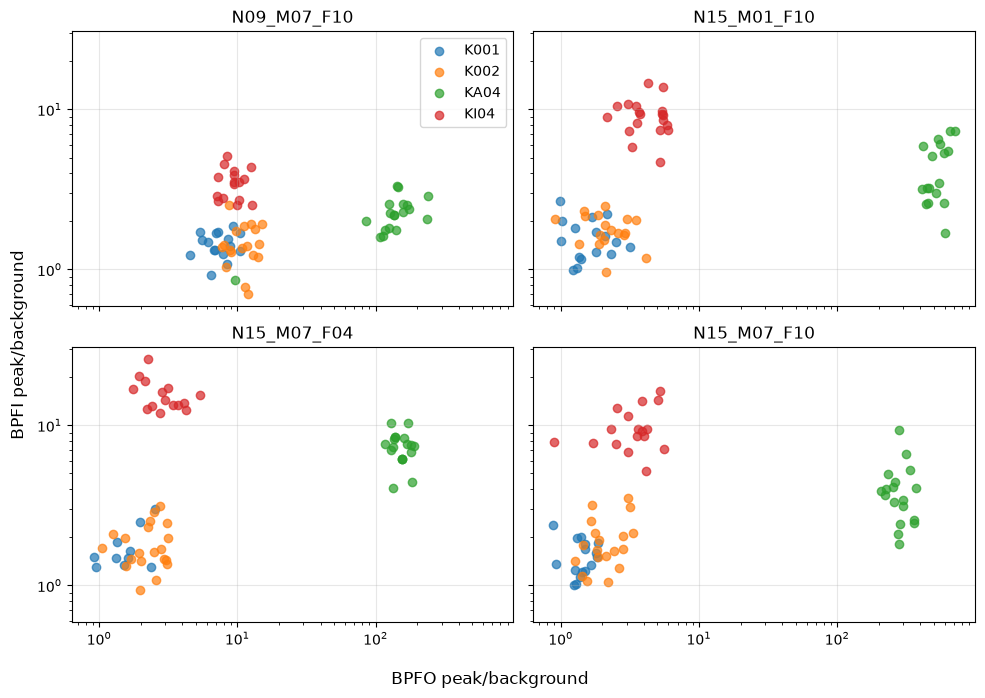

In [27]:
envelope_results = bpfo_results.merge(
    bpfi_results[["recording_id", "BPFI peak/background"]],
    on="recording_id", how="left", validate="one_to_one"
)
assert envelope_results["BPFI peak/background"].notna().all()

fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharex=True, sharey=True)

for ax, (setting, group) in zip(axes.flat, envelope_results.groupby(settings)):
    for bearing, rows in group.groupby("bearing_id"):
        ax.scatter(
            rows["BPFO peak/background"], rows["BPFI peak/background"],
            label=bearing, alpha=0.7
        )
    ax.set(title="_".join(setting), xscale="log", yscale="log")
    ax.grid(alpha=0.3)

axes[0, 0].legend()
fig.supxlabel("BPFO peak/background")
fig.supylabel("BPFI peak/background")
plt.tight_layout()

In [28]:
guard_checks = []

for bearing, x in signals.items():
    for duration in [0.05, 0.1, 0.2]:
        f, p = envelope_psd(x, 9000, 11000, guard_s=duration)
        guard_checks.append({
            "Bearing": bearing,
            "Guard (s)": duration,
            "BPFO ratio": peak_ratio(f, p, bpfo_reference),
            "BPFI ratio": peak_ratio(f, p, bpfi_reference)
        })

pd.DataFrame(guard_checks).pivot(
    index="Bearing", columns="Guard (s)",
    values=["BPFO ratio", "BPFI ratio"]
).round(2)

BPFO ratio                 BPFI ratio              
Guard (s)       0.05    0.10    0.20       0.05   0.10   0.20
Bearing                                                      
K001            1.23    1.40    1.49       1.96   2.00   1.99
K002            2.12    2.14    1.77       1.55   1.53   1.63
KA04          339.08  357.12  360.17       2.27   2.44   2.17
KI04            5.45    5.23    5.68      16.75  16.26  15.67

In [29]:
padding_checks = []

for bearing, x in signals.items():
    for duration in [0.05, 0.1, 0.2]:
        f, p = envelope_psd(x, 9000, 11000, padding_s=duration)
        padding_checks.append({
            "Bearing": bearing,
            "Padding (s)": duration,
            "BPFO ratio": peak_ratio(f, p, bpfo_reference),
            "BPFI ratio": peak_ratio(f, p, bpfi_reference)
        })

pd.DataFrame(padding_checks).pivot(
    index="Bearing", columns="Padding (s)",
    values=["BPFO ratio", "BPFI ratio"]
).round(2)

BPFO ratio                 BPFI ratio              
Padding (s)       0.05    0.10    0.20       0.05   0.10   0.20
Bearing                                                        
K001              1.40    1.40    1.40       2.00   2.00   2.00
K002              2.14    2.14    2.14       1.53   1.53   1.53
KA04            357.12  357.12  357.12       2.44   2.44   2.44
KI04              5.23    5.23    5.23      16.26  16.26  16.26

In [30]:
record = example_records.iloc[0]
x = signals[record["bearing_id"]]
envelope = vibration_envelope(x)

window_size = int(fs)
guard = int(0.1 * fs)
window_numbers = np.arange(x.size // window_size)
starts = window_numbers * window_size

keep = (starts >= guard) & (starts + window_size <= x.size - guard)
window_numbers = window_numbers[keep]
envelope_windows = np.array([
    envelope[start:start + window_size] for start in starts[keep]
])

print("Recording:", record["recording_id"])
print("Retained window numbers:", window_numbers)
print("Envelope window shape:", envelope_windows.shape)

Recording: N15_M07_F10_K001_1
Retained window numbers: [1 2]
Envelope window shape: (2, 64000)


In [31]:
f, power = welch(
    envelope_windows, fs=fs, window="hann",
    nperseg=window_size, noverlap=0, detrend="constant", axis=1
)
speed_scale = float(record["speed_setting_rpm"]) / 1500

window_features = pd.DataFrame({
    "recording_id": record["recording_id"],
    "window_no": window_numbers,
    "BPFO peak/background": [
        peak_ratio(f, p, bpfo_reference * speed_scale) for p in power
    ],
    "BPFI peak/background": [
        peak_ratio(f, p, bpfi_reference * speed_scale) for p in power
    ]
})

window_features.round(2)

,recording_id,window_no,BPFO peak/background,BPFI peak/background
0,N15_M07_F10_K001_1,1,2.10,4.55
1,N15_M07_F10_K001_1,2,2.05,2.24


In [32]:
rows = []
window_size, guard = int(fs), int(0.1 * fs)

for _, record in development.iterrows():
    x = load_signal(project / "data/raw/paderborn" / record["relative_path"])
    envelope = vibration_envelope(x)
    numbers = np.arange(x.size // window_size)
    starts = numbers * window_size
    keep = (starts >= guard) & (starts + window_size <= x.size - guard)
    windows = np.array([
        envelope[start:start + window_size] for start in starts[keep]
    ])
    if not len(windows):
        continue

    f, power = welch(
        windows, fs=fs, window="hann", nperseg=window_size,
        noverlap=0, detrend="constant", axis=1
    )
    scale = float(record["speed_setting_rpm"]) / 1500

    for number, p in zip(numbers[keep], power):
        rows.append({
            "recording_id": record["recording_id"],
            "window_no": number,
            "BPFO peak/background": peak_ratio(f, p, bpfo_reference * scale),
            "BPFI peak/background": peak_ratio(f, p, bpfi_reference * scale)
        })

envelope_features = pd.DataFrame(rows)
assert not envelope_features.duplicated(["recording_id", "window_no"]).any()
assert np.isfinite(envelope_features.select_dtypes("number")).all().all()

print("Recordings:", envelope_features["recording_id"].nunique())
print("Retained windows:", len(envelope_features))

Recordings: 272
Retained windows: 544


In [33]:
base_features = pd.read_csv(
    project / "data/processed/development_features.csv"
)
keys = ["recording_id", "window_no"]

combined_features = envelope_features.merge(
    base_features, on=keys, how="left",
    validate="one_to_one", indicator=True
)

assert combined_features["_merge"].eq("both").all(), "Unmatched windows."
assert set(combined_features["recording_id"]) == set(development["recording_id"])
assert combined_features["partition"].eq("development").all()

combined_features = combined_features.drop(columns="_merge")
combined_features.to_csv(
    project / "data/processed/development_features_with_envelope.csv",
    index=False
)

combined_features.groupby(["bearing_id", "condition"]).agg(
    recordings=("recording_id", "nunique"),
    windows=("window_no", "count")
)

,,recordings,windows
bearing_id,condition,,
K001,healthy,58,116
K002,healthy,75,150
KA04,faulty,72,144
KI04,faulty,67,134


In [34]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix

validation_pairs = [
    ("K001", "KA04"), ("K001", "KI04"),
    ("K002", "KA04"), ("K002", "KI04")
]
y = combined_features["condition"].map({"healthy": 0, "faulty": 1})
assert y.notna().all()


def evaluate_features(columns, estimator=None):
    X = combined_features[columns]
    results = []

    for bearings in validation_pairs:
        validation = combined_features["bearing_id"].isin(bearings)
        model = clone(estimator) if estimator is not None else make_pipeline(
        StandardScaler(),
        LogisticRegression(class_weight="balanced", max_iter=1000)
        )
        model.fit(X.loc[~validation], y.loc[~validation])
        prediction = model.predict(X.loc[validation])
        tn, fp, fn, tp = confusion_matrix(
            y.loc[validation], prediction, labels=[0, 1]
        ).ravel()

        results.append({
            "Validation bearings": ", ".join(bearings),
            "Balanced accuracy (%)": 50 * (tn / (tn + fp) + tp / (tp + fn)),
            "Fault recall (%)": 100 * tp / (tp + fn),
            "False alarms": fp,
            "Missed faults": fn
        })

    return pd.DataFrame(results)


shape_columns = ["Crest factor", "Pearson kurtosis"]
shape_results = evaluate_features(shape_columns)
shape_results.round(2)

,Validation bearings,Balanced accuracy (%),Fault recall (%),False alarms,Missed faults
0,"K001, KA04",85.34,100.00,34,0
1,"K001, KI04",86.34,76.12,4,32
2,"K002, KA04",67.65,65.97,46,49
3,"K002, KI04",88.06,76.12,0,32


In [35]:
envelope_columns = ["BPFO peak/background", "BPFI peak/background"]

feature_comparison = pd.concat({
    "Waveform shape": shape_results,
    "Envelope": evaluate_features(envelope_columns),
    "Shape + envelope": evaluate_features(shape_columns + envelope_columns)
}, names=["Feature set"])

feature_comparison.round(2)

Validation bearings  Balanced accuracy (%)  \
Feature set                                                     
Waveform shape   0          K001, KA04                  85.34   
                 1          K001, KI04                  86.34   
                 2          K002, KA04                  67.65   
                 3          K002, KI04                  88.06   
Envelope         0          K001, KA04                  94.56   
                 1          K001, KI04                  62.69   
                 2          K002, KA04                  91.97   
                 3          K002, KI04                  61.19   
Shape + envelope 0          K001, KA04                  94.56   
                 1          K001, KI04                  87.69   
                 2          K002, KA04                  87.65   
                 3          K002, KI04                  88.06   

                    Fault recall (%)  False alarms  Missed faults  
Feature set                                                        
Waveform shape   0            100.00            34              0  
                 1             76.12             4             32  
                 2             65.97            46             49  
                 3             76.12             0             32  
Envelope         0             98.61            11              2  
                 1             25.37             0            100  
                 2             98.61            22              2  
                 3             22.39             0            104  
Shape + envelope 0             98.61            11              2  
                 1             75.37             0             33  
                 2             99.31            36              1  
                 3             76.12             0             32

In [36]:
validation = combined_features["bearing_id"].isin(["K001", "KI04"])
X = combined_features[shape_columns + envelope_columns]

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=1000)
)
model.fit(X.loc[~validation], y.loc[~validation])
prediction = model.predict(X.loc[validation])

audit = combined_features.loc[
    validation, settings + ["recording_id", "bearing_id"]
].copy()
audit["Missed faults"] = y.loc[validation].eq(1) & (prediction == 0)
faults = audit[audit["bearing_id"].eq("KI04")]

summary = faults.groupby(settings).agg(
    recordings=("recording_id", "nunique"),
    windows=("recording_id", "size"),
    missed_faults=("Missed faults", "sum")
)
summary["Fault recall (%)"] = 100 * (
    1 - summary["missed_faults"] / summary["windows"]
)
summary.round(2)

recordings  windows  missed_faults  \
speed_code torq_code force_code                                       
N09        M07       F10                 16       32             32   
N15        M01       F10                 19       38              0   
           M07       F04                 15       30              1   
                     F10                 17       34              0   

                                 Fault recall (%)  
speed_code torq_code force_code                    
N09        M07       F10                     0.00  
N15        M01       F10                   100.00  
           M07       F04                    96.67  
                     F10                   100.00

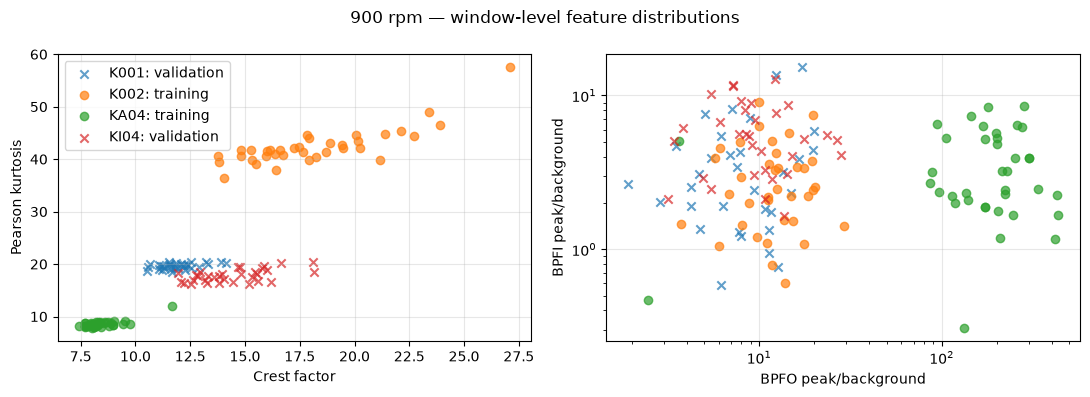

In [37]:
subset = combined_features[combined_features["speed_code"].eq("N09")]
held_bearings = ["K001", "KI04"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, columns in zip(axes, [shape_columns, envelope_columns]):
    for bearing, group in subset.groupby("bearing_id"):
        held_out = bearing in held_bearings
        role = "validation" if held_out else "training"
        ax.scatter(
            group[columns[0]], group[columns[1]],
            marker="x" if held_out else "o",
            label=f"{bearing}: {role}", alpha=0.7
        )
    ax.set(xlabel=columns[0], ylabel=columns[1])
    ax.grid(alpha=0.3)

axes[1].set(xscale="log", yscale="log")
axes[0].legend()
fig.suptitle("900 rpm — window-level feature distributions")
plt.tight_layout()

In [38]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier

forest = RandomForestClassifier(
    n_estimators=200, max_depth=3, min_samples_leaf=20,
    class_weight="balanced", random_state=42
)

model_comparison = pd.concat({
    "Logistic regression": feature_comparison.loc["Shape + envelope"],
    "Random Forest": evaluate_features(
        shape_columns + envelope_columns, forest
    )
}, names=["Model"])

model_comparison.round(2)

Validation bearings  Balanced accuracy (%)  \
Model                                                              
Logistic regression 0          K001, KA04                  94.56   
                    1          K001, KI04                  87.69   
                    2          K002, KA04                  87.65   
                    3          K002, KI04                  88.06   
Random Forest       0          K001, KA04                  97.50   
                    1          K001, KI04                  86.19   
                    2          K002, KA04                  80.99   
                    3          K002, KI04                  88.06   

                       Fault recall (%)  False alarms  Missed faults  
Model                                                                 
Logistic regression 0             98.61            11              2  
                    1             75.37             0             33  
                    2             99.31            36              1  
                    3             76.12             0             32  
Random Forest       0             99.31             5              1  
                    1             72.39             0             37  
                    2             99.31            56              1  
                    3             76.12             0             32

In [39]:
forest_feature_comparison = pd.concat({
    "Waveform shape": evaluate_features(shape_columns, forest),
    "Shape + envelope": model_comparison.loc["Random Forest"]
}, names=["Feature set"])

forest_feature_comparison.round(2)

Validation bearings  Balanced accuracy (%)  \
Feature set                                                     
Waveform shape   0          K001, KA04                  88.45   
                 1          K001, KI04                  87.20   
                 2          K002, KA04                  75.65   
                 3          K002, KI04                  88.06   
Shape + envelope 0          K001, KA04                  97.50   
                 1          K001, KI04                  86.19   
                 2          K002, KA04                  80.99   
                 3          K002, KI04                  88.06   

                    Fault recall (%)  False alarms  Missed faults  
Feature set                                                        
Waveform shape   0             99.31            26              1  
                 1             76.12             2             32  
                 2             99.31            72              1  
                 3             76.12             0             32  
Shape + envelope 0             99.31             5              1  
                 1             72.39             0             37  
                 2             99.31            56              1  
                 3             76.12             0             32

In [40]:
tables = project / "reports/tables"
tables.mkdir(parents=True, exist_ok=True)

comparisons = {
    "envelope_feature_comparison": feature_comparison,
    "envelope_model_comparison": model_comparison,
    "forest_envelope_feature_comparison": forest_feature_comparison
}

for name, results in comparisons.items():
    results.to_csv(tables / f"{name}.csv")

In [41]:
columns = shape_columns + envelope_columns
reference_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=1000)
)
predictions = []

for bearings in validation_pairs:
    validation = combined_features["bearing_id"].isin(bearings)
    model = clone(reference_model)
    model.fit(combined_features.loc[~validation, columns], y.loc[~validation])

    fold = combined_features.loc[
        validation, keys + ["bearing_id", "condition"] + settings
    ].copy()
    fold["Validation bearings"] = ", ".join(bearings)
    fold["Fault probability"] = model.predict_proba(
        combined_features.loc[validation, columns]
    )[:, 1]
    predictions.append(fold)

window_predictions = pd.concat(predictions, ignore_index=True)
window_predictions.head()

,recording_id,window_no,bearing_id,condition,speed_code,torq_code,force_code,Validation bearings,Fault probability
0,N09_M07_F10_K001_2,1,K001,healthy,N09,M07,F10,"K001, KA04",0.044939
1,N09_M07_F10_K001_2,2,K001,healthy,N09,M07,F10,"K001, KA04",0.062239
2,N09_M07_F10_K001_3,1,K001,healthy,N09,M07,F10,"K001, KA04",0.442746
3,N09_M07_F10_K001_3,2,K001,healthy,N09,M07,F10,"K001, KA04",0.974104
4,N09_M07_F10_K001_4,1,K001,healthy,N09,M07,F10,"K001, KA04",0.197839


In [42]:
recording_predictions = window_predictions.groupby(
    ["Validation bearings", "recording_id", "bearing_id", "condition"] + settings,
    as_index=False
).agg(
    windows=("window_no", "size"),
    fault_score=("Fault probability", "mean")
)
recording_predictions["Predicted faulty"] = (
    recording_predictions["fault_score"] >= 0.5
)

results = []

for bearings, group in recording_predictions.groupby("Validation bearings"):
    tn, fp, fn, tp = confusion_matrix(
        group["condition"].eq("faulty"),
        group["Predicted faulty"], labels=[False, True]
    ).ravel()

    results.append({
        "Validation bearings": bearings,
        "Healthy recordings": tn + fp,
        "Faulty recordings": tp + fn,
        "Balanced accuracy (%)": 50 * (tn / (tn + fp) + tp / (tp + fn)),
        "Fault recall (%)": 100 * tp / (tp + fn),
        "False alarms": fp,
        "Missed faults": fn
    })

recording_results = pd.DataFrame(results)
recording_results.round(2)

,Validation bearings,Healthy recordings,Faulty recordings,Balanced accuracy (%),Fault recall (%),False alarms,Missed faults
0,"K001, KA04",58,72,95.86,98.61,4,1
1,"K001, KI04",58,67,88.06,76.12,0,16
2,"K002, KA04",75,72,87.31,98.61,18,1
3,"K002, KI04",75,67,88.06,76.12,0,16


In [43]:
misses = recording_predictions[
    recording_predictions["condition"].eq("faulty")
    & ~recording_predictions["Predicted faulty"]
]

misses.groupby(
    ["Validation bearings", "bearing_id"] + settings
).size().rename("Missed recordings").to_frame()

,,,,,Missed recordings
Validation bearings,bearing_id,speed_code,torq_code,force_code,
"K001, KA04",KA04,N09,M07,F10,1
"K001, KI04",KI04,N09,M07,F10,16
"K002, KA04",KA04,N09,M07,F10,1
"K002, KI04",KI04,N09,M07,F10,16


In [44]:
misses.loc[
    misses["bearing_id"].eq("KA04"),
    ["Validation bearings", "recording_id", "fault_score"]
].round(3)

,Validation bearings,recording_id,fault_score
20,"K001, KA04",N09_M07_F10_KA04_13,0.361
277,"K002, KA04",N09_M07_F10_KA04_13,0.495


In [45]:
window_predictions.to_csv(
    tables / "envelope_logistic_window_predictions.csv", index=False
)
recording_predictions.to_csv(
    tables / "envelope_logistic_recording_predictions.csv", index=False
)
recording_results.to_csv(
    tables / "envelope_logistic_recording_results.csv", index=False
)

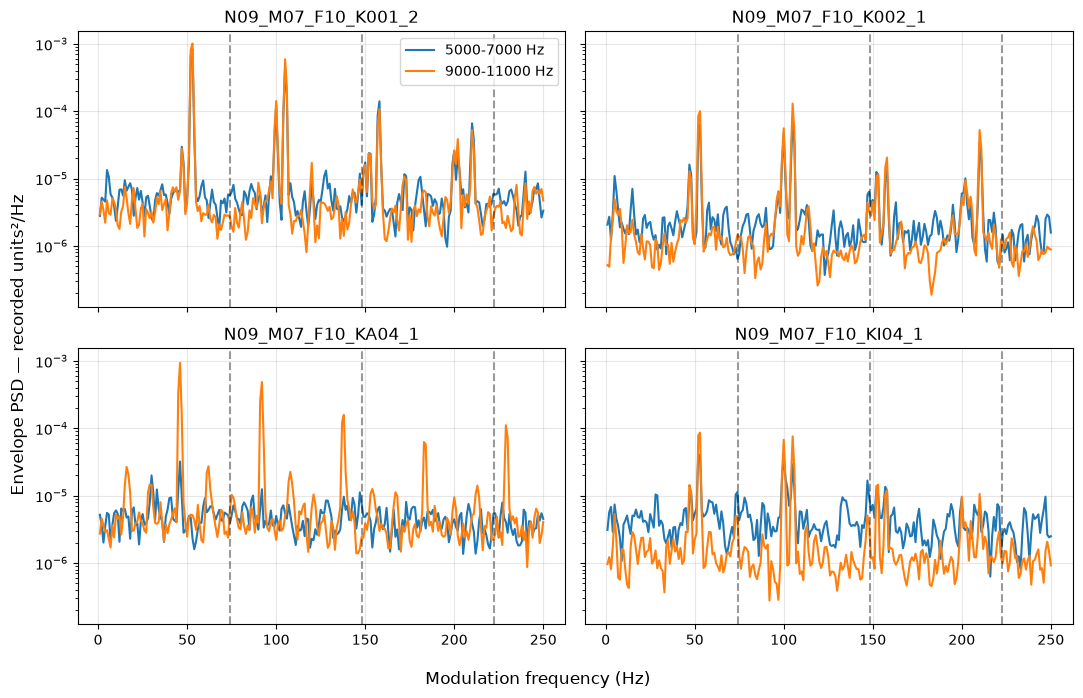

In [46]:
records_900 = development[
    development["speed_code"].eq("N09")
].sort_values(["bearing_id", "recording_no"]).drop_duplicates("bearing_id")

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True, sharey=True)

for ax, (_, record) in zip(axes.flat, records_900.iterrows()):
    x = load_signal(project / "data/raw/paderborn" / record["relative_path"])
    target = bpfi_reference * float(record["speed_setting_rpm"]) / 1500

    for low, high in [(5000, 7000), (9000, 11000)]:
        f, p = envelope_psd(x, low, high)
        view = (f >= 1) & (f <= 250)
        ax.semilogy(f[view], p[view], label=f"{low}-{high} Hz")

    for harmonic in [1, 2, 3]:
        ax.axvline(harmonic * target, color="black", ls="--", alpha=0.4)

    ax.set_title(record["recording_id"])
    ax.grid(alpha=0.3)

axes[0, 0].legend()
fig.supxlabel("Modulation frequency (Hz)")
fig.supylabel("Envelope PSD — recorded units²/Hz")
plt.tight_layout()

In [47]:
harmonic_checks = []

for _, record in records_900.iterrows():
    x = load_signal(project / "data/raw/paderborn" / record["relative_path"])
    target = bpfi_reference * float(record["speed_setting_rpm"]) / 1500

    for low, high in [(5000, 7000), (9000, 11000)]:
        f, p = envelope_psd(x, low, high)

        for harmonic in [1, 2, 3]:
            harmonic_checks.append({
                "Bearing": record["bearing_id"],
                "Carrier": f"{low}-{high} Hz",
                "Harmonic": harmonic,
                "Peak/background": peak_ratio(f, p, harmonic * target)
            })

harmonic_comparison = pd.DataFrame(harmonic_checks)
harmonic_comparison.pivot(
    index="Bearing", columns=["Carrier", "Harmonic"],
    values="Peak/background"
).round(2)

Carrier  5000-7000 Hz             9000-11000 Hz            
Harmonic            1     2     3             1     2     3
Bearing                                                    
K001             1.76  4.88  1.64          1.32  4.66  1.97
K002             0.95  3.87  0.90          1.40  5.05  1.33
KA04             1.19  2.67  1.70          2.07  0.73  1.10
KI04             2.74  3.59  2.54          5.09  4.66  2.37

In [48]:
harmonic_comparison.to_csv(
    tables / "bpfi_harmonics_900rpm_examples.csv", index=False
)

third_checks = []

for _, record in development[development["speed_code"].eq("N09")].iterrows():
    x = load_signal(project / "data/raw/paderborn" / record["relative_path"])
    target = 3 * bpfi_reference * float(record["speed_setting_rpm"]) / 1500

    for low, high in [(5000, 7000), (9000, 11000)]:
        f, p = envelope_psd(x, low, high)
        third_checks.append({
            "recording_id": record["recording_id"],
            "Bearing": record["bearing_id"],
            "Carrier": f"{low}-{high} Hz",
            "Peak/background": peak_ratio(f, p, target)
        })

third_results = pd.DataFrame(third_checks)
third_results.to_csv(tables / "bpfi_third_harmonic_900rpm.csv", index=False)

third_results.groupby(["Carrier", "Bearing"])["Peak/background"].agg(
    ["count", "median", "min", "max"]
).round(2)

count  median   min   max
Carrier       Bearing                           
5000-7000 Hz  K001        16    1.60  0.90  2.32
              K002        18    1.39  0.90  1.79
              KA04        19    1.51  1.09  2.24
              KI04        16    2.43  1.16  4.16
9000-11000 Hz K001        16    1.71  0.89  2.13
              K002        18    1.39  0.81  2.44
              KA04        19    1.13  0.63  2.00
              KI04        16    2.30  0.97  3.04

In [49]:
sideband_checks = []

for _, record in development[development["speed_code"].eq("N09")].iterrows():
    x = load_signal(project / "data/raw/paderborn" / record["relative_path"])
    rpm = float(record["speed_setting_rpm"])
    target = bpfi_reference * rpm / 1500
    shaft_hz = rpm / 60

    for low, high in [(5000, 7000), (9000, 11000)]:
        f, p = envelope_psd(x, low, high)
        sideband_checks.append({
            "recording_id": record["recording_id"],
            "Bearing": record["bearing_id"],
            "Carrier": f"{low}-{high} Hz",
            "Lower sideband": peak_ratio(f, p, target - shaft_hz),
            "Upper sideband": peak_ratio(f, p, target + shaft_hz)
        })

sideband_results = pd.DataFrame(sideband_checks)
sideband_results.to_csv(tables / "bpfi_sidebands_900rpm.csv", index=False)

sideband_results.groupby(["Carrier", "Bearing"])[
    ["Lower sideband", "Upper sideband"]
].agg(["median", "min", "max"]).round(2)

Lower sideband             Upper sideband               
                              median   min   max         median    min     max
Carrier       Bearing                                                         
5000-7000 Hz  K001              1.26  0.73  1.79           1.25   0.79    1.69
              K002              1.81  1.10  2.69           1.41   0.67    2.84
              KA04              1.57  0.95  3.52           1.88   0.95    2.55
              KI04              1.75  1.32  2.54           3.50   1.44    5.16
9000-11000 Hz K001              1.28  0.58  1.72           1.30   0.70    3.30
              K002              1.66  1.18  4.13           1.51   1.01    3.88
              KA04              3.54  1.71  8.34          84.52  10.22  136.11
              KI04              1.36  0.89  2.39           1.89   1.25    4.55